In [3]:
import torch
import matplotlib.pyplot as plt

from spikinggamma.spike.base import compute_linspace_bucket_decay_rates
from spikinggamma.spike.sigma_delta import update_buckets


T = 80
decay_factor = 0.35
# bucket_decay_rates = torch.tensor([0.9])
bucket_decay_rates = compute_linspace_bucket_decay_rates(n_buckets=5, decay_factor=decay_factor)
n_buckets = len(bucket_decay_rates)

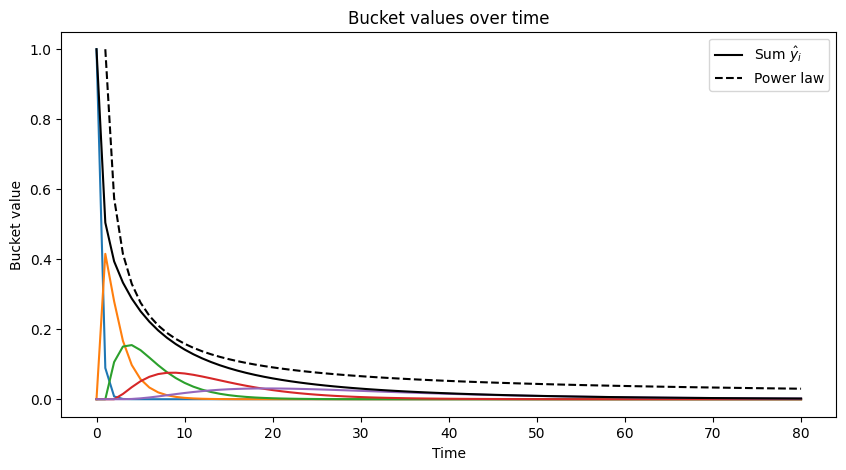

In [4]:
buckets = torch.zeros(1, 1, n_buckets)
buckets_log = []

z = []
ts = torch.linspace(0, T, steps=T+1, dtype=torch.int)
for t in ts:
    if t == 0: # Provide some input at the beginning
        x = torch.ones(1, 1)
        z = [1]
    else:
        x = torch.zeros(1, 1)
        z.append(z[-1]*0.9)
    buckets = update_buckets(buckets, x, bucket_decay_rates)
    buckets_log.append(buckets.clone())

buckets_log = torch.stack(buckets_log)
plt.figure(figsize=(10, 5))
lines = plt.plot(buckets_log[:, 0, 0, :])
# for i, line in enumerate(lines):
#     line.set_label(f'Bucket $\hat{{y}}_i^{i}$')
plt.plot(buckets_log[:, 0, 0, :].sum(dim=1), label='Sum $\hat{y}_i$', color='black')
plt.plot(ts, ts**-0.8, label='Power law', color='black', linestyle='dashed')
# plt.plot(ts, z, color='red', label='Input $x_i$')
plt.xlabel('Time')
plt.ylabel('Bucket value')
plt.title('Bucket values over time')
plt.legend()
plt.show()

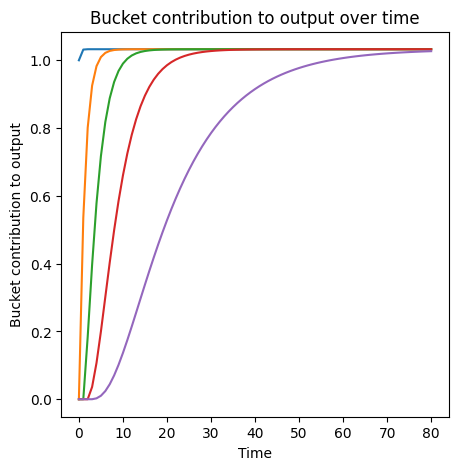

In [81]:

buckets = torch.zeros(1, 1, n_buckets)
buckets_sum = torch.zeros(1, 1, n_buckets)
buckets_sums = []
ts = torch.linspace(0, T, steps=T+1, dtype=torch.int)
for t in ts:
    if t == 0: # Provide some input at the beginning
        x = torch.ones(1, 1)
    else:
        x = torch.zeros(1, 1)
    buckets = update_buckets(buckets, x, bucket_decay_rates)
    buckets_sum = (buckets_sum + buckets)
    buckets_sums.append(buckets_sum.clone())

buckets_sums = torch.stack(buckets_sums)
plt.figure(figsize=(5, 5))
# plot bins
plt.plot(buckets_sums[:, 0, 0, :])
plt.xlabel('Time')
plt.ylabel('Bucket contribution to output')
plt.title('Bucket contribution to output over time')

plt.show()